In [ ]:
#A1) Load the CSV into a pandas DataFrame.
import pandas as pd

df=pd.read_csv("Canadian_Health_Survey_Sample.csv")


In [ ]:
#A2) Show .head(), .info(), and .describe(include='all')
df.head()
df.info()
df.describe(include='all')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 850 entries, 0 to 849
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Province          850 non-null    object 
 1   Gender            850 non-null    object 
 2   Age               850 non-null    int64  
 3   Income            816 non-null    float64
 4   BMI               808 non-null    float64
 5   PhysicalActivity  825 non-null    float64
 6   Smoking           850 non-null    object 
 7   SelfRatedHealth   850 non-null    object 
 8   StressLevel       825 non-null    float64
dtypes: float64(4), int64(1), object(4)
memory usage: 59.9+ KB


,Province,Gender,Age,Income,BMI,PhysicalActivity,Smoking,SelfRatedHealth,StressLevel
count,850,850,850.000000,816.000000,808.000000,825.000000,850,850,825.000000
unique,10,6,NaN,NaN,NaN,NaN,6,5,NaN
top,Quebec,Male,NaN,NaN,NaN,NaN,No,Good,NaN
freq,100,230,NaN,NaN,NaN,NaN,552,258,NaN
mean,NaN,NaN,49.517647,77461.917892,27.488861,3.511394,NaN,NaN,5.294545
std,NaN,NaN,18.192604,22497.833440,5.064344,1.925825,NaN,NaN,2.121156
min,NaN,NaN,18.000000,5000.000000,13.500000,0.000000,NaN,NaN,1.000000
25%,NaN,NaN,33.000000,63438.000000,24.000000,2.100000,NaN,NaN,4.000000
50%,NaN,NaN,49.000000,78130.000000,27.300000,3.500000,NaN,NaN,5.000000
75%,NaN,NaN,66.000000,90529.500000,30.900000,4.700000,NaN,NaN,7.000000


A3) Identify one quantitative attribute and one qualitative attribute; explain why.

Quantitative Attribute- Income

Income is a quantitative attribute because it signifies a numeric value on which arithmetic operations such as addition, multiplication, division, etc. can be operated on it.

Qualitative Attribute- Province

Province is a qualitative unordered attribute because it describes a category or a label. Arithmetic operations cannot be performed on the province values.



In [ ]:
'''B1) Standardize categorical values:
• Normalize Gender values to {'Male','Female'}
• Normalize Smoking to {'Yes','No'}'''

df['Gender']=df['Gender'].str.capitalize()
df['Gender']=df['Gender'].replace({
  'M':'Male',
  'F':'Female',
})


df['Smoking']=df['Smoking'].str.capitalize()
df['Smoking']=df['Smoking'].replace({
  'Y':'Yes',
  'N':'No',
})
df.to_csv("cleaned_dataset.csv", index=False)

In [ ]:
#B2) Handle missing values (justify choices): BMI, Income, StressLevel, PhysicalActivity – choose dropna or imputation.
df=df.dropna(subset=['BMI','StressLevel'])
df['Income']=df['Income'].fillna(df['Income'].median())
df['PhysicalActivity']=df['PhysicalActivity'].fillna(df['PhysicalActivity'].median())

df.to_csv("cleaned_dataset.csv", index=False)

I choose to drop BMI and StressLevel because they are the key indicators for determining the overall health of Canadians. They provide direct measures of physical and mental well-being, which are central to our analysis. Income and PhysicalActivity, on the other hand, may influence health indirectly and can be considered secondary factors. While these variables contribute context and help explain variability in health outcomes, they are not as critical for calculating the primary health proxy, so missing values in these columns can be reasonably imputed without significantly biasing the analysis.

In [ ]:
#B3) Enforce data types: Age (int), Income (float), BMI (float), StressLevel (int).
df['Age']=df['Age'].astype(int)
df['Income']=df['Income'].astype(float)
df['BMI']=df['BMI'].astype(float)
df['StressLevel']=df['StressLevel'].astype(int)

df.to_csv("cleaned_dataset.csv", index=False)

In [ ]:
'''B4) Create derived columns:
• BMI_Category ∈ {'Underweight','Normal','Overweight','Obese'}
• IncomeBracket ∈ {'<50k','50–80k','80–110k','>110k'}'''

def categorize_bmi(bmi):
  if bmi<18.5:
    return 'Underweight'
  elif 18.5<=bmi<25:
    return 'Normal'
  elif 25<=bmi<30:
    return 'Overweight'
  else:
    return 'Obese'
  
def categorize_income(income):
  if income<50000:
    return '<50k'
  elif 50000<=income<=80000:
    return '50k-80k'
  elif 80000<income<=110000:
    return '80k-110k'
  else:
    return '>110k'
  
  

In [ ]:
df['BMI_Category']=df['BMI'].apply(categorize_bmi)
df['IncomeBracket']=df['Income'].apply(categorize_income)

df.to_csv("cleaned_dataset.csv", index=False)

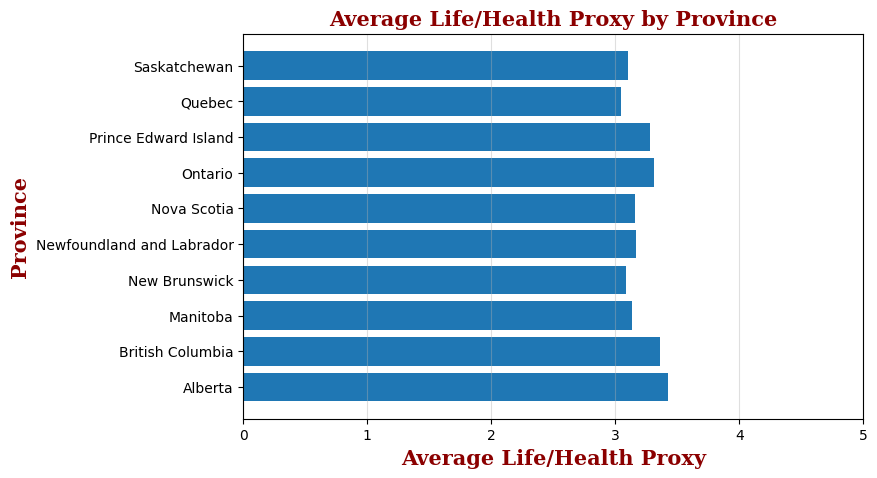

In [ ]:
import matplotlib.pyplot as plt

df['HealthScore'] = df['SelfRatedHealth'].map({
    'Poor': 1, 'Fair': 2, 'Good': 3, 'Very Good': 4, 'Excellent': 5
})

values = df.groupby('Province')['HealthScore'].mean()

font = {
    'family': 'serif',
    'color': 'darkred',
    'weight': 'bold',
    'size': 15,
}

plt.figure(figsize=(8, 5))

plt.barh(values.index, values.values)  

plt.title('Average Life/Health Proxy by Province',fontdict=font)
plt.xlabel('Average Life/Health Proxy', fontdict=font)
plt.ylabel('Province', fontdict=font)

plt.xlim(0, 5)
plt.grid(axis='x',alpha=0.4)

plt.show()


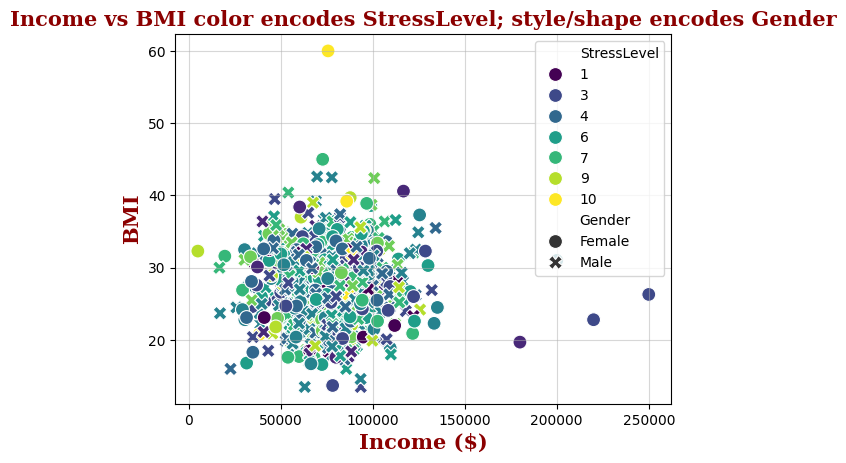

In [ ]:
'''C2) Scatter: Income vs BMI; color encodes StressLevel; style/shape encodes Gender. Include
colorbar/legend and readable axis labels.'''

import seaborn as sns

BMI_values = df['BMI'].values       # 1D array
Income_values = df['Income'].values 

sns.scatterplot(
  data=df,
  x='Income',
  y='BMI',
  hue='StressLevel',
  style='Gender',
  s=100,
  palette='viridis'
)
plt.xlabel('Income ($)',fontdict=font)
plt.ylabel('BMI',fontdict=font)
plt.title('Income vs BMI color encodes StressLevel; style/shape encodes Gender',fontdict=font)
plt.grid(True,alpha=0.5)
plt.show()

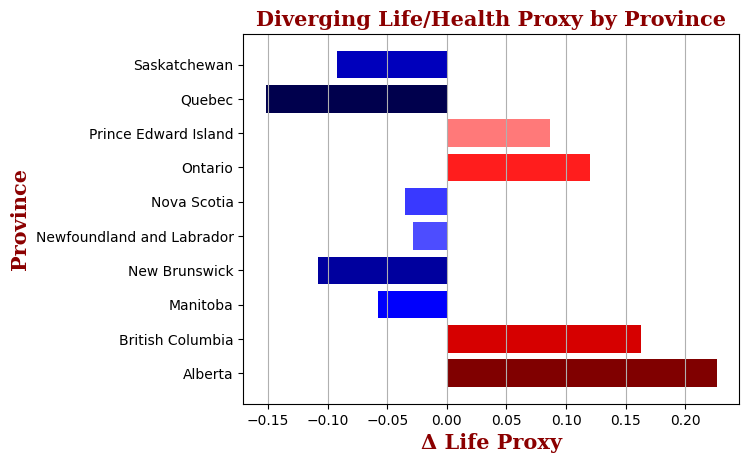

In [ ]:
'''C3) Diverging visualization: for each Province, compute ΔLifeProxy = Province
mean(SelfRatedHealth_num) – overall mean; plot a horizontal bar with a diverging
colormap.'''
import numpy as np

province_mean=df.groupby('Province')['HealthScore'].mean()
overall_mean=df['HealthScore'].mean()

deltaLifeProxy=province_mean-overall_mean

normalized = (deltaLifeProxy - deltaLifeProxy.min()) / (deltaLifeProxy.max() - deltaLifeProxy.min())
colors = plt.cm.seismic(normalized)

plt.barh(
  deltaLifeProxy.index,
  deltaLifeProxy.values,
  color=colors
  
)
plt.xlabel('Δ Life Proxy',fontdict=font)
plt.ylabel('Province',fontdict=font)
plt.title('Diverging Life/Health Proxy by Province',fontdict=font)
plt.grid(axis='x')
plt.show()


C4) Briefly explain design choices using principles (color scales, cognitive load, contiguity).

C1 – Bar chart: Average Life/Health Proxy by Province

-> Color scales: Single color used for bars since we are encoding only 1 variable (Province)

-> Cognitive load: Low since using the same color avoids overloading the viewer. Avoids split attention and exhibits spatial contiguity.

-> Contiguity: Spatial mapping of bar height to value is clear; Bars are aligned side-by-side, making it easy to compare provinces.

-> Title & X-Y Labels: Horizontal axis shows provinces, vertical axis shows average health. Explicit x/y-axis labels and title support close coupling of data and context, reducing mental effort.

C2 - Scatter: Income vs BMI

-> Color: Continuous color shows the different levels of stress, with 10 being the highest level of stress and 1 the lowest, which allows viewers to perceive higher/lower stress intuitively.

-> Shape: Different shapes encoded for types of Gender,'X' depicts the Male Gender and 'O' depicts the Female gender, to better visualize the stress level among males and females seperately.

-> Cognitive Load: By separating shape and color, the plot leverages dual-channel encoding, allowing viewers to interpret two variables at once without confusion, also exhibiting temporal contiguity.

-> Spatial contiguity: Position encodes Income (x-axis) and BMI (y-axis), which are directly relevant to understanding physical and economic health relationships. Plotting points in a scatterplot ensures spatial coherence — nearby points relate to nearby values.

C3 - Diverging horizontal bar (ΔLifeProxy)

-> Color: Clearly shows which provinces are above vs below the overall mean, leveraging attentive color differences.

-> Horizontal bars: Makes reading the Δ values easier, aligns with the length principle of bars. The zero line also provides a visual reference, reducing cognitive effort in interpreting positive vs negative differences.

-> Cognitive load: Diverging colors and alignment reduce mental effort by grouping negative vs positive deviations intuitively.

-> Contiguity: Avoids split attention and exhibits spatial contiguity. Provinces are stacked vertically, Δ values are represented by bar length, which is directly proportional to the metric.




D1) Discuss observed relationships (e.g., association between Income and BMI; differences by Province/Gender).

C1 – Bar chart: Average Life/Health Proxy by Province

In C1, all the provinces are averaging 3 on the Health Score which substitutes to Good on the scale of Self Rated Health. Some provinces (e.g., Ontario) have slightly higher average Life/Health proxy, while others (e.g., Quebec) are lower.
This suggests regional differences in self-rated health, which could be due to socioeconomic, environmental, or lifestyle factors. 

C2 - Income vs BMI

There seems to be no strong correlation between income and bmi. Majority of results show a normal to overweight bmi for citizens in the income bracket of (50k-100k). 
StressLevel shows some pattern: higher StressLevel values (lighter points on the viridis scale) sometimes cluster around certain BMI or Income ranges, suggesting that stress may be more common in mid-income or very high BMI ranges in this dataset.

C3 - Diverging horizontal bar (ΔLifeProxy)

The horizontal diverging bar chart highlights which provinces are above or below the overall mean:

Positive ΔLifeProxy → province is healthier than average
Negative ΔLifeProxy → province is less healthy than average

Provinces such as Quebec or New Brunswick show a negative deviation from the overall mean of Life Proximation while provinces such as Alberta show a positive deviation from the overall Life proximation average.


D2) Identify one potential confound or limitation due to data quality (missingness, outliers, category ambiguity).

A potential limitation of this dataset is the presence of outliers in Income or BMI, which can skew averages and distort relationships between variables.

Missing values in key columns like BMI, Income, StressLevel, or PhysicalActivity can reduce the effective sample size and introduce bias. For example, if certain groups (e.g., a particular province or gender) have more missing entries, the averages or scatterplot patterns may not accurately represent the true population. This limitation can affect the validity of comparisons across provinces, genders, or stress levels.

Derived columns like BMI_Category and IncomeBracket require grouping continuous numeric data into discrete categories. This introduces ambiguity because the choice of bin boundaries is somewhat arbitrary. For example, someone with a BMI of 24.9 is classified as “Normal,” while 25.0 is “Overweight,” even though the actual difference is minimal. Similarly, income brackets may not reflect meaningful socioeconomic differences. Such categorization can reduce the precision of the data, potentially obscuring subtle patterns and affecting the interpretation of averages or comparisons across groups.
